In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import RadiusNeighborsRegressor


In [2]:
# Load Dataset
file = r"C:\OEAS805\HW3\CBP_TWQM_MAIN_WQ_2021_2026_surface.csv"
data = pd.read_csv(file)
print(data.columns)


Index(['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project',
       'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate',
       'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM',
       'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType',
       'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue',
       'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC',
       'Details', 'TierLevel'],
      dtype='str')


In [3]:
print(data["Parameter"].unique())

<ArrowStringArray>
[    'CHLA',      'DIN',       'DO',      'DON',      'DOP',       'KD',
     'NH4F',    'NO23F',     'NO2F',     'NO3F',       'PC',       'PH',
     'PHEO',       'PN',     'PO4F',       'PP', 'SALINITY',   'SECCHI',
  'SIGMA_T',   'SPCOND',      'TDN',      'TDP',       'TN',      'TON',
       'TP',      'TSS',    'WTEMP']
Length: 27, dtype: str


In [ ]:
#Target Variable is CHLA, I want to be able to predict Chlorophyll-a Concentration given 
#other parameter values
#Predictors: DIN,PO4F, and Tss

In [4]:
#Originally wrote: X  = data.loc[data["Parameter"] == "DIN", "MeasureValue"]
                  #y = data.loc[data["Parameter"] == "CHLA", "MeasureValue"]
#This did not work, asked Claude to fix based on error to give  code below

wide = data.pivot_table(index=["Station", "SampleDate"],
                        columns="Parameter",
                        values="MeasureValue").reset_index()
predictors = ["DIN","PO4F", "TSS"]
paired = wide[predictors + ["CHLA"]].dropna()

X = paired[predictors]   
y = paired["CHLA"]
print(len(paired), "paired samples")

42 paired samples


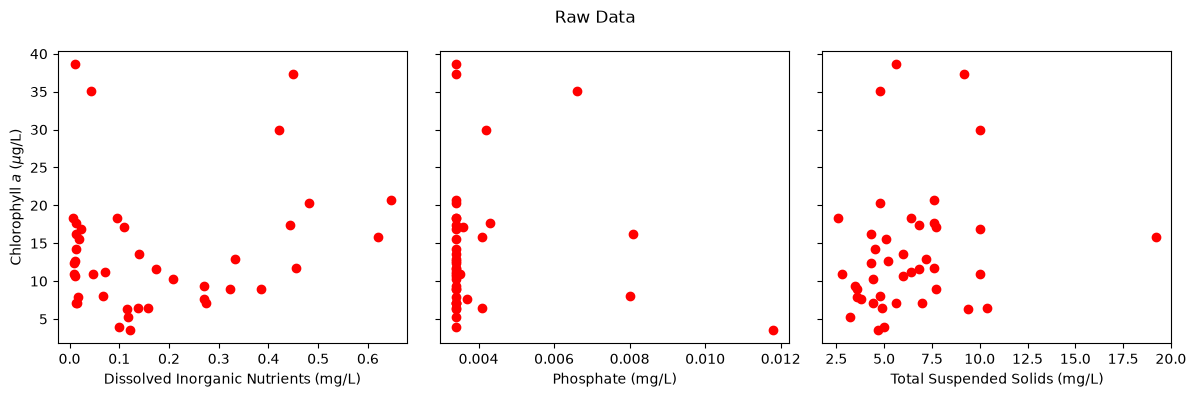

In [5]:
# Here I plot the original dataset to show visualize all the data
labels = {"DIN": "Dissolved Inorganic Nutrients (mg/L)",
          "PO4F": "Phosphate (mg/L)",
          "TSS": "Total Suspended Solids (mg/L)"}

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, predictors):
    ax.scatter(X[name], y, color='red')
    ax.set_xlabel(labels[name])
axes[0].set_ylabel(r'Chlorophyll $a$ ($\mu$g/L)')
fig.suptitle('Raw Data')
plt.tight_layout()
plt.show()

CHLA = +9.27*DIN +28.50*PO4F +0.30*TSS +9.64
Mean Squared Error = 117.60
Coefficient of determination (R-squared) = -0.15


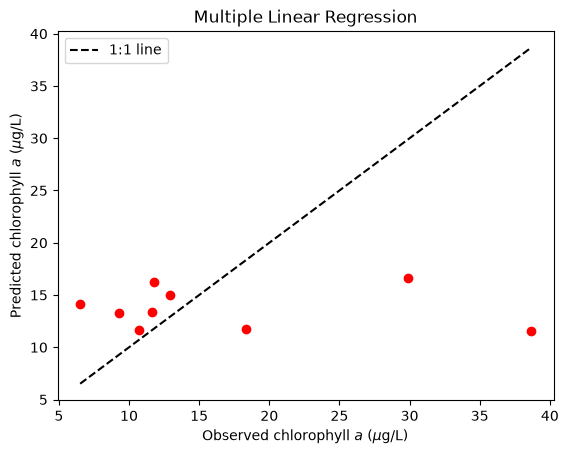

In [6]:
# Here I run a linear regression with 80% of the data used to train and tested against 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)

regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)

y_pred = regr.predict(X_test)

terms = ' '.join('%+.2f*%s' % (c, n) for c, n in zip(regr.coef_, predictors))
print('CHLA = %s %+.2f' % (terms, regr.intercept_))
print('Mean Squared Error = %.2f' % mean_squared_error(y_test, y_pred))
print('Coefficient of determination (R-squared) = %.2f' % r2_score(y_test, y_pred))

# Observed vs predicted: points on the dashed 1:1 line are perfect predictions
plt.scatter(y_test, y_pred, color='red')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'k--', label='1:1 line')
plt.xlabel(r'Observed chlorophyll $a$ ($\mu$g/L)')
plt.ylabel(r'Predicted chlorophyll $a$ ($\mu$g/L)')
plt.title('Multiple Linear Regression')
plt.legend()
plt.show()

In [7]:
#Try Log Transforming CHLA as the scatter shows they are grouped towards low concentrations
paired = paired[paired["CHLA"] > 0]    
X = paired[predictors]
ylog = np.log10(paired["CHLA"])

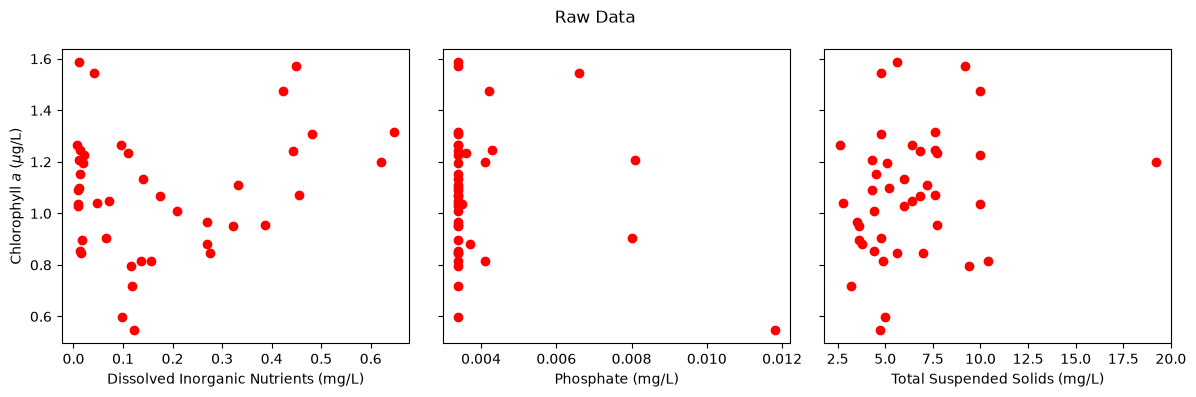

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, predictors):
    ax.scatter(X[name], ylog, color='red')
    ax.set_xlabel(labels[name])
axes[0].set_ylabel(r'Chlorophyll $a$ ($\mu$g/L)')
fig.suptitle('Raw Data')
plt.tight_layout()
plt.show()

log(CHLA) = +0.21*DIN -17.83*PO4F +0.01*TSS +1.02
Mean Squared Error = 0.06
Coefficient of determination (R-squared) = -0.17


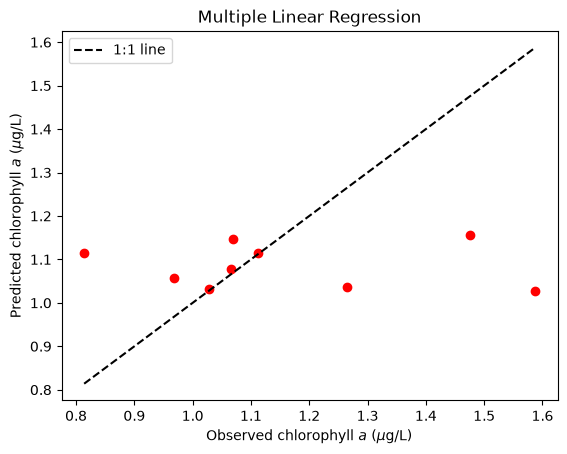

In [9]:
# Here I run a linear regression with 80% of the data used to train and tested against 20%
X_train, X_test, y_train, y_test = train_test_split(X, ylog, test_size=0.2, random_state=9)

regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)

y_pred = regr.predict(X_test)

# Fitted equation with all three coefficients
terms = ' '.join('%+.2f*%s' % (c, n) for c, n in zip(regr.coef_, predictors))
print('log(CHLA) = %s %+.2f' % (terms, regr.intercept_))
print('Mean Squared Error = %.2f' % mean_squared_error(y_test, y_pred))
print('Coefficient of determination (R-squared) = %.2f' % r2_score(y_test, y_pred))

# Observed vs predicted: points on the dashed 1:1 line are perfect predictions
plt.scatter(y_test, y_pred, color='red')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'k--', label='1:1 line')
plt.xlabel(r'Observed chlorophyll $a$ ($\mu$g/L)')
plt.ylabel(r'Predicted chlorophyll $a$ ($\mu$g/L)')
plt.title('Multiple Linear Regression')
plt.legend()
plt.show()

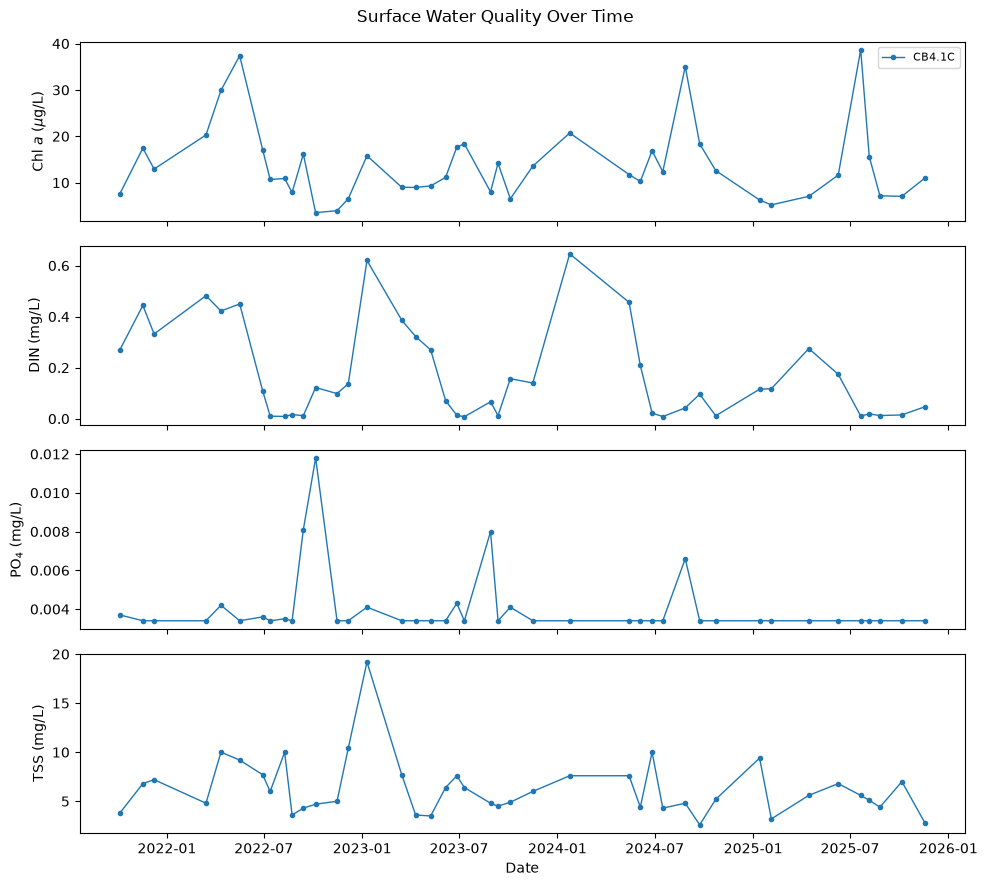

In [10]:
# Investigating a potential lag response...
wide["SampleDate"] = pd.to_datetime(wide["SampleDate"])

variables = {"CHLA": r"Chl $a$ ($\mu$g/L)",
             "DIN":  "DIN (mg/L)",
             "PO4F": r"PO$_4$ (mg/L)",
             "TSS":  "TSS (mg/L)"}

fig, axes = plt.subplots(len(variables), 1, figsize=(10, 9), sharex=True)
for ax, (var, label) in zip(axes, variables.items()):
    for station, grp in wide.groupby("Station"):
        series = grp[["SampleDate", var]].dropna().sort_values("SampleDate")
        ax.plot(series["SampleDate"], series[var], 'o-', markersize=3,
                linewidth=1, label=station)
    ax.set_ylabel(label)

axes[0].legend(fontsize=8, ncol=4)
axes[-1].set_xlabel("Date")
fig.suptitle("Surface Water Quality Over Time")
plt.tight_layout()
plt.show()

In [11]:
cols = ["CHLA", "DIN", "PO4F", "TSS"]
wide["SampleDate"] = pd.to_datetime(wide["SampleDate"])

for var in cols:
    sub = wide.dropna(subset=[var]).sort_values("SampleDate")
    gap = sub.groupby("Station")["SampleDate"].diff().dt.days.mean()
    print('%-5s: %.0f days between samples on average' % (var, gap))

CHLA : 37 days between samples on average
DIN  : 37 days between samples on average
PO4F : 37 days between samples on average
TSS  : 37 days between samples on average


In [ ]:
#Gap is too large to expect to see uptake response lag-correlation not likely.

Choose a number for k:  9


Train R-squared: 0.27
Test R-squared:  0.01


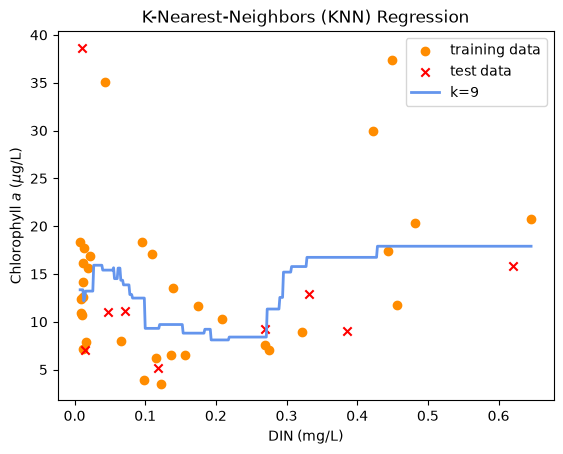

In [12]:
#Non-Linear K-Nearest-Neighbors Regression
k  = int(input('Choose a number for k: '))
X = paired[["DIN"]]     # quotes + double brackets: 2D, as scikit-learn requires
y = paired["CHLA"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=14)

# Fit regression model on the training data only
regr_1 = KNeighborsRegressor(n_neighbors=k)
regr_1.fit(X_train, y_train)
print("Train R-squared: {0:.2f}".format(regr_1.score(X_train, y_train)))
print("Test R-squared:  {0:.2f}".format(regr_1.score(X_test, y_test)))

# Predict along a smooth range of DIN values to draw the KNN curve
X_grid = pd.DataFrame({"DIN": np.linspace(X["DIN"].min(), X["DIN"].max(), 500)})
y_grid = regr_1.predict(X_grid)

# Plot the results
plt.figure()
plt.scatter(X_train, y_train, c="darkorange", label="training data")
plt.scatter(X_test, y_test, c="red", marker="x", label="test data")
plt.plot(X_grid, y_grid, color="cornflowerblue", label="k=" + str(k), linewidth=2)
plt.xlabel("DIN (mg/L)")
plt.ylabel(r"Chlorophyll $a$ ($\mu$g/L)")
plt.title("K-Nearest-Neighbors (KNN) Regression")
plt.legend()
plt.show()

In [ ]:
# k = 9 had the highest r2 based on the random state of 14 so this was used for final result

Choose a number for hidden nodes:  25


Train R-squared: 0.79
Test R-squared:  -0.41


C:\Users\sam_w\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10000) reached and the optimization hasn't converged yet.
  warnings.warn(


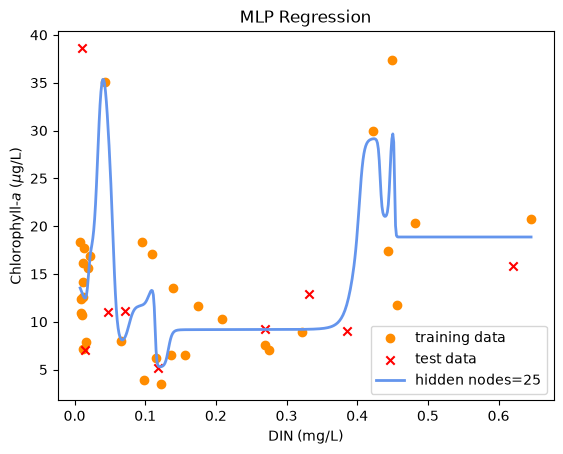

In [30]:
#Non-Linear Multi-Layer Perceptron
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Choose a number of hidden nodes...
n  = int(input('Choose a number for hidden nodes: '))
X = paired[["DIN"]]
y = paired["CHLA"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=14)

# Fit regression model on the training data only
regr_2 = make_pipeline(StandardScaler(),
                       MLPRegressor(hidden_layer_sizes=(n, n), activation='tanh',
                                    max_iter=10000, random_state=14))
regr_2.fit(X_train, y_train)
print("Train R-squared: {0:.2f}".format(regr_2.score(X_train, y_train)))
print("Test R-squared:  {0:.2f}".format(regr_2.score(X_test, y_test)))

# Predict along a smooth range of DIN values to draw the MLP curve
X_grid = pd.DataFrame({"DIN": np.linspace(X["DIN"].min(), X["DIN"].max(), 500)})
y_grid = regr_2.predict(X_grid)

# Plot the results
plt.figure()
plt.scatter(X_train, y_train, c="darkorange", label="training data")
plt.scatter(X_test, y_test, c="red", marker="x", label="test data")
plt.plot(X_grid, y_grid, color="cornflowerblue", label="hidden nodes=" + str(n), linewidth=2)
plt.xlabel("DIN (mg/L)")
plt.ylabel(r"Chlorophyll-$a$ ($\mu$g/L)")
plt.title("MLP Regression")
plt.legend()
plt.show()


In [ ]:
#n = 10,Train R-squared: 0.65
        #Test R-squared:  -1.02


#n = 14, Train R-squared: 0.63
        #Test R-squared:  -1.10

#n = 25, Train R-squared: 0.79
        #Test R-squared:  -0.41

#n = 50 Train R-squared: 0.91
        #Test R-squared:  -0.73

#n = 100, Train R-squared: 0.87
        #Test R-squared:  -0.53

In [ ]:
#25 nodes seems to be the best model we can get showing high variability at low (0.0-0.1) and (0.4-0.5) with relatively stable points otherwise.